In [2]:
# Kendi çalışma notu: Rastgelelik içeren işlemlerde sabit tohum kullan.
%pip install xgboost lightgbm catboost

import random
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings("ignore")

from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans,AgglomerativeClustering,DBSCAN
from sklearn.neighbors import NearestNeighbors
from sklearn.metrics import silhouette_score,davies_bouldin_score,calinski_harabasz_score
from scipy.cluster.hierarchy import dendrogram,linkage

from sklearn.model_selection import train_test_split,GridSearchCV,StratifiedKFold,cross_val_score,cross_validate
from sklearn.tree import DecisionTreeClassifier,plot_tree
from sklearn.ensemble import (RandomForestClassifier,AdaBoostClassifier,
                              GradientBoostingClassifier,HistGradientBoostingClassifier)
from sklearn.metrics import accuracy_score,roc_auc_score,ConfusionMatrixDisplay
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier
from catboost import CatBoostClassifier

SEED = 42
random.seed(SEED)
np.random.seed(SEED)

  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.

[notice] A new release of pip is available: 23.0.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


     ---------------------------------------- 0.0/100.2 MB ? eta -:--:--
     ---------------------------------------- 0.0/100.2 MB ? eta -:--:--
     ---------------------------------------- 0.0/100.2 MB ? eta -:--:--
     -------------------------------------- 0.1/100.2 MB 880.9 kB/s eta 0:01:54
     -------------------------------------- 0.1/100.2 MB 880.9 kB/s eta 0:01:54
     -------------------------------------- 0.1/100.2 MB 880.9 kB/s eta 0:01:54
     ---------------------------------------- 0.2/100.2 MB 1.1 MB/s eta 0:01:32
     ---------------------------------------- 0.2/100.2 MB 1.1 MB/s eta 0:01:32
     ---------------------------------------- 0.2/100.2 MB 1.1 MB/s eta 0:01:32
     ---------------------------------------- 0.5/100.2 MB 1.5 MB/s eta 0:01:07
     ---------------------------------------- 0.5/100.2 MB 1.5 MB/s eta 0:01:07
     ---------------------------------------- 0.7/100.2 MB 1.8 MB/s eta 0:00:55
     ---------------------------------------- 1.0/100.2 MB 2.

#### Kümeleme: Mall_Customers.csv

In [3]:
df = pd.read_csv("Mall_Customers.csv")
print("Veri seti boyutu: ", df.shape)
df.info()

Veri seti boyutu:  (200, 5)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 5 columns):
 #   Column                  Non-Null Count  Dtype 
---  ------                  --------------  ----- 
 0   CustomerID              200 non-null    int64 
 1   Gender                  200 non-null    object
 2   Age                     200 non-null    int64 
 3   Annual Income (k$)      200 non-null    int64 
 4   Spending Score (1-100)  200 non-null    int64 
dtypes: int64(4), object(1)
memory usage: 7.9+ KB


In [4]:
df.isnull().sum()

CustomerID                0
Gender                    0
Age                       0
Annual Income (k$)        0
Spending Score (1-100)    0
dtype: int64

In [5]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
CustomerID,200.0,100.50,57.879185,1.0,50.75,100.5,150.25,200.0
Age,200.0,38.85,13.969007,18.0,28.75,36.0,49.00,70.0
Annual Income (k$),200.0,60.56,26.264721,15.0,41.50,61.5,78.00,137.0
Spending Score (1-100),200.0,50.20,25.823522,1.0,34.75,50.0,73.00,99.0


#### sayısal sütunları alıp dolduralım

In [6]:
df.set_index("CustomerID",inplace=True)
features = ["Age","Annual Income (k$)","Spending Score (1-100)"]
imputer = SimpleImputer(strategy="mean")
df_imputed = pd.DataFrame(imputer.fit_transform(df[features]),columns=features,index=df.index)
print("Eksik değer kaldı mı:", df_imputed.isnull().sum().sum())

Eksik değer kaldı mı: 0


#### scale edelim

In [7]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(df_imputed)
pd.DataFrame(X_scaled,columns=features,index=df_imputed.index).head(2)

,Age,Annual Income (k$),Spending Score (1-100)
CustomerID,,,
1,-1.424569,-1.738999,-0.434801
2,-1.281035,-1.738999,1.195704


#### K-Means: elbow ve silhouette

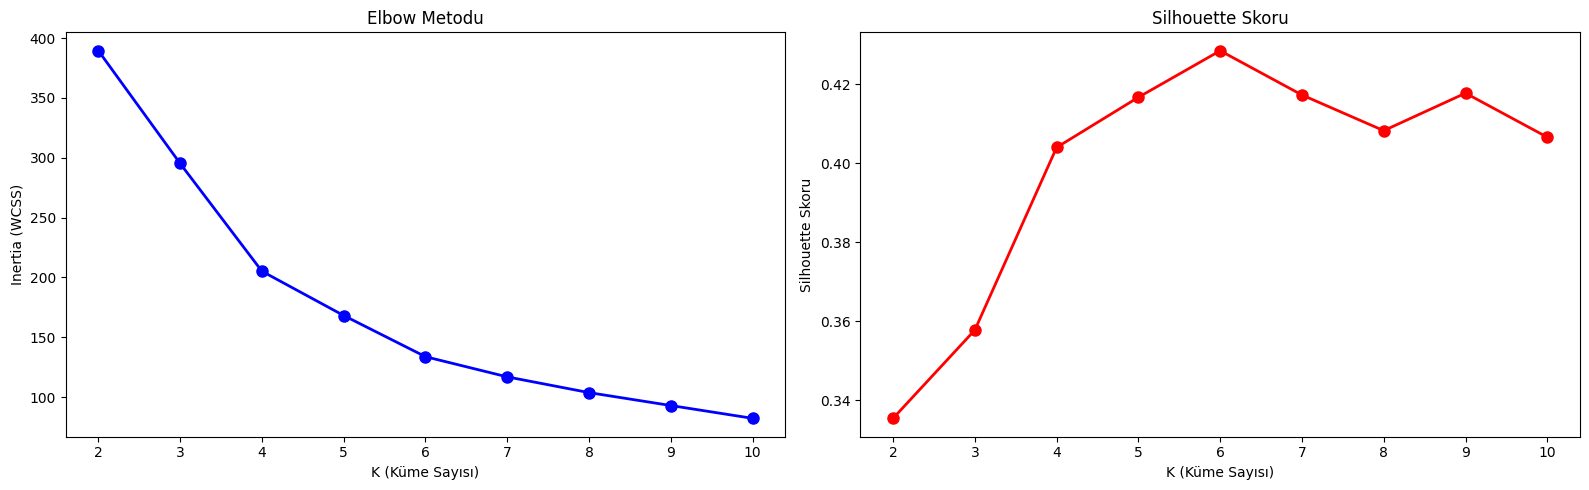

En iyi silhouette skoru: 0.4284167762892593
Optimum K: 6


In [8]:
inertia = []
silhouette_scores = []
K_range = range(2,11)

for k in K_range:
    kmeans = KMeans(n_clusters=k,random_state=SEED,n_init=10)
    labels = kmeans.fit_predict(X_scaled)
    inertia.append(kmeans.inertia_)
    silhouette_scores.append(silhouette_score(X_scaled,labels))

fig, axes = plt.subplots(1,2,figsize=(16,5))
axes[0].plot(K_range,inertia,"bo-",linewidth=2,markersize=8)
axes[0].set_title("Elbow Metodu")
axes[0].set_xlabel("K (Küme Sayısı)")
axes[0].set_ylabel("Inertia (WCSS)")
axes[1].plot(K_range,silhouette_scores,"ro-",linewidth=2,markersize=8)
axes[1].set_title("Silhouette Skoru")
axes[1].set_xlabel("K (Küme Sayısı)")
axes[1].set_ylabel("Silhouette Skoru")
plt.tight_layout()
plt.show()

optimal_k = K_range[np.argmax(silhouette_scores)]
print("En iyi silhouette skoru:", max(silhouette_scores))
print("Optimum K:", optimal_k)

In [9]:
kmeans = KMeans(n_clusters=optimal_k,random_state=SEED,n_init=10)
kmeans_labels = kmeans.fit_predict(X_scaled)

print("Silhouette Skoru:", silhouette_score(X_scaled,kmeans_labels))
print("Davies-Bouldin İndeksi:", davies_bouldin_score(X_scaled,kmeans_labels))
print("Calinski-Harabasz Skoru:", calinski_harabasz_score(X_scaled,kmeans_labels))
print(pd.Series(kmeans_labels).value_counts().sort_index())

Silhouette Skoru: 0.4284167762892593
Davies-Bouldin İndeksi: 0.8253539040983219
Calinski-Harabasz Skoru: 135.10210365783408
0    45
1    39
2    33
3    39
4    23
5    21
Name: count, dtype: int64


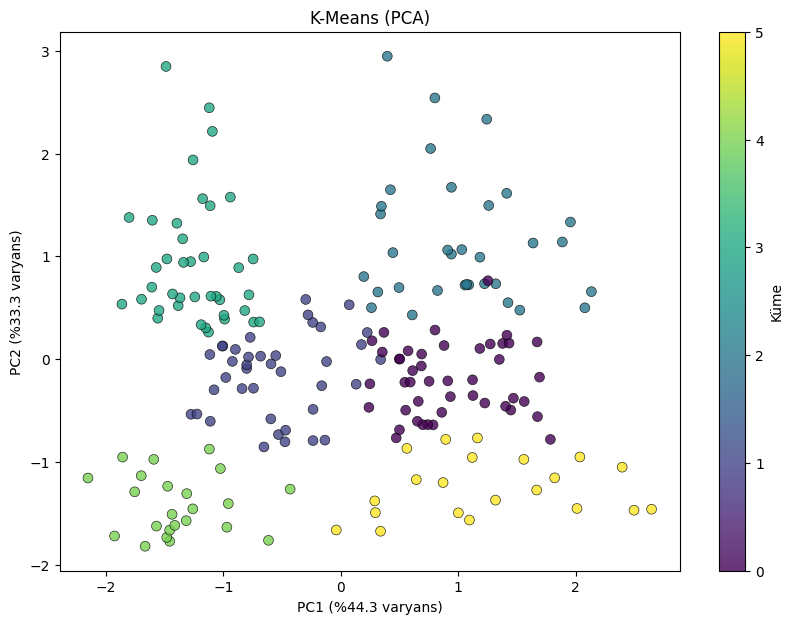

In [10]:
pca = PCA(n_components=2,random_state=SEED)
X_pca = pca.fit_transform(X_scaled)

plt.figure(figsize=(10,7))
scatter = plt.scatter(X_pca[:,0],X_pca[:,1],c=kmeans_labels,cmap="viridis",alpha=0.8,s=50,edgecolors="k",linewidth=0.5)
plt.colorbar(scatter,label="Küme")
plt.title("K-Means (PCA)")
plt.xlabel(f"PC1 (%{pca.explained_variance_ratio_[0]*100:.1f} varyans)")
plt.ylabel(f"PC2 (%{pca.explained_variance_ratio_[1]*100:.1f} varyans)")
plt.show()

#### kümeler hangi müşteriler

In [11]:
profile = df_imputed.copy()
profile["Küme"] = kmeans_labels
profile.groupby("Küme")[features].mean().round(1).assign(Kişi=profile["Küme"].value_counts().sort_index())

,Age,Annual Income (k$),Spending Score (1-100),Kişi
Küme,,,,
0,56.3,54.3,49.1,45
1,26.8,57.1,48.1,39
2,41.9,88.9,17.0,33
3,32.7,86.5,82.1,39
4,25.0,25.3,77.6,23
5,45.5,26.3,19.4,21


#### hiyerarşik kümeleme

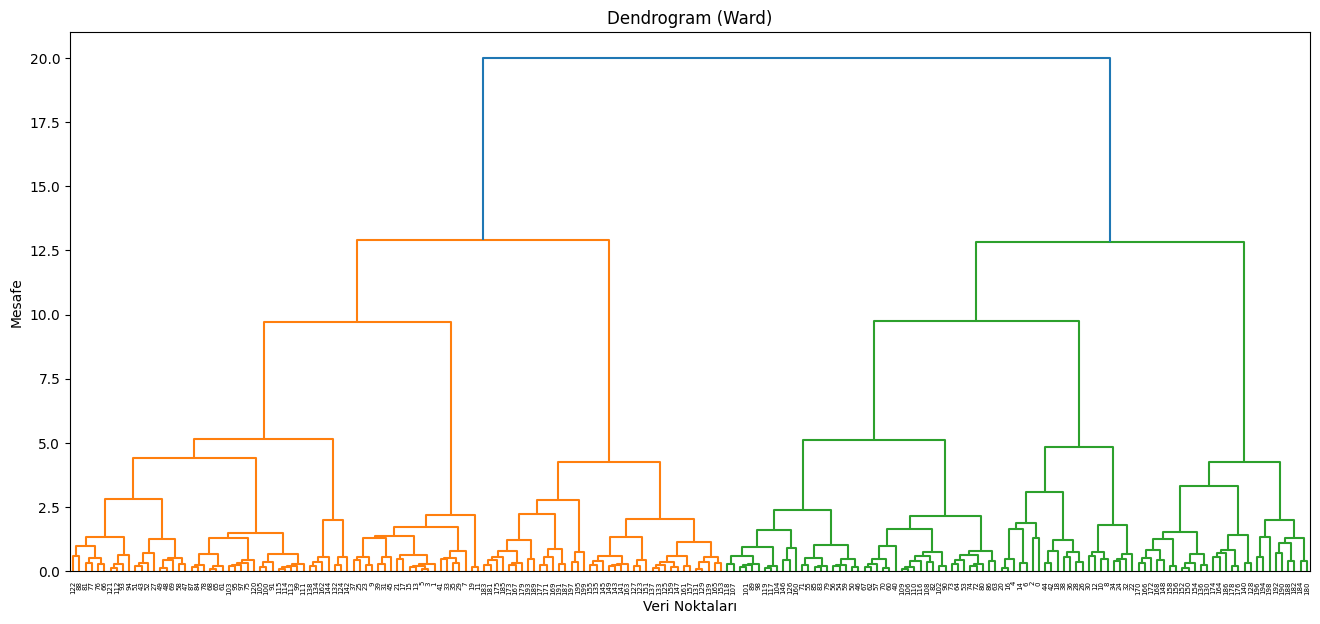

In [12]:
plt.figure(figsize=(16,7))
linked = linkage(X_scaled,method="ward")
dendrogram(linked,orientation="top",distance_sort="descending",show_leaf_counts=False,truncate_mode="level",p=10)
plt.title("Dendrogram (Ward)")
plt.xlabel("Veri Noktaları")
plt.ylabel("Mesafe")
plt.show()

In [13]:
agg = AgglomerativeClustering(n_clusters=optimal_k,linkage="ward")
agg_labels = agg.fit_predict(X_scaled)

print("Silhouette Skoru:", silhouette_score(X_scaled,agg_labels))
print("Davies-Bouldin İndeksi:", davies_bouldin_score(X_scaled,agg_labels))
print("Calinski-Harabasz Skoru:", calinski_harabasz_score(X_scaled,agg_labels))
print(pd.Series(agg_labels).value_counts().sort_index())

Silhouette Skoru: 0.4201169558789579
Davies-Bouldin İndeksi: 0.8521020845733146
Calinski-Harabasz Skoru: 127.98645433956887
0    45
1    45
2    39
3    28
4    22
5    21
Name: count, dtype: int64


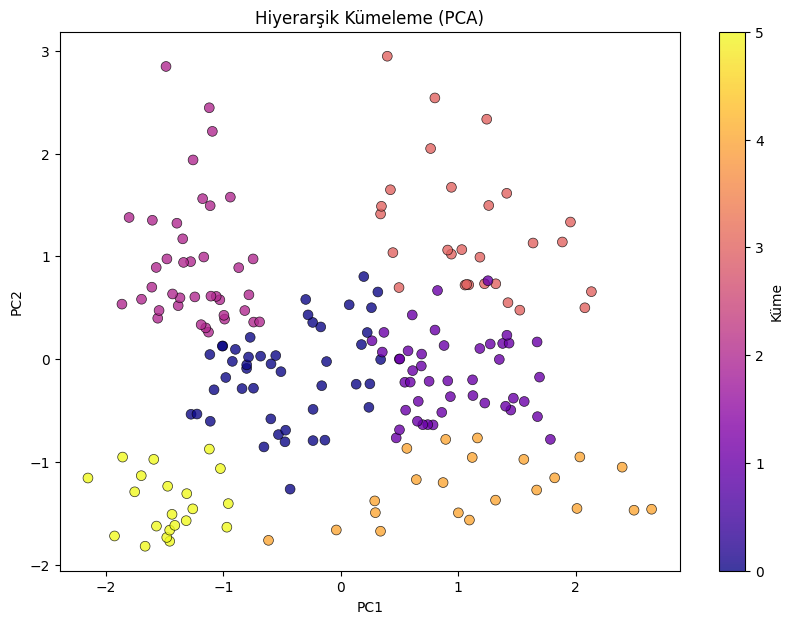

In [14]:
plt.figure(figsize=(10,7))
scatter = plt.scatter(X_pca[:,0],X_pca[:,1],c=agg_labels,cmap="plasma",alpha=0.8,s=50,edgecolors="k",linewidth=0.5)
plt.colorbar(scatter,label="Küme")
plt.title("Hiyerarşik Kümeleme (PCA)")
plt.xlabel("PC1")
plt.ylabel("PC2")
plt.show()

#### DBSCAN

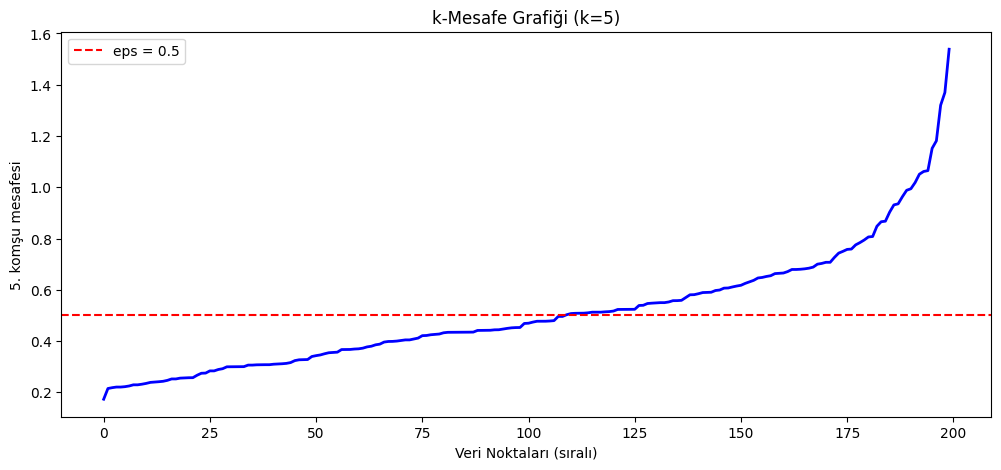

In [15]:
neighbors = NearestNeighbors(n_neighbors=5).fit(X_scaled)
distances, _ = neighbors.kneighbors(X_scaled)
distances = np.sort(distances[:,4])

plt.figure(figsize=(12,5))
plt.plot(distances,"b-",linewidth=2)
plt.axhline(y=0.5,color="r",linestyle="--",label="eps = 0.5")
plt.title("k-Mesafe Grafiği (k=5)")
plt.xlabel("Veri Noktaları (sıralı)")
plt.ylabel("5. komşu mesafesi")
plt.legend()
plt.show()

In [16]:
dbscan = DBSCAN(eps=0.5,min_samples=5)
dbscan_labels = dbscan.fit_predict(X_scaled)

n_clusters_db = len(set(dbscan_labels))-(1 if -1 in dbscan_labels else 0)
n_noise = (dbscan_labels==-1).sum()
mask = dbscan_labels != -1

print("Küme sayısı:", n_clusters_db)
print("Gürültü sayısı:", n_noise)
print("Gürültü oranı:", n_noise/len(dbscan_labels))
print("Silhouette Skoru:", silhouette_score(X_scaled[mask],dbscan_labels[mask]))
print("Davies-Bouldin İndeksi:", davies_bouldin_score(X_scaled[mask],dbscan_labels[mask]))
print("Calinski-Harabasz Skoru:", calinski_harabasz_score(X_scaled[mask],dbscan_labels[mask]))
print(pd.Series(dbscan_labels).value_counts().sort_index())

Küme sayısı: 6
Gürültü sayısı: 60
Gürültü oranı: 0.3
Silhouette Skoru: 0.481714917862304
Davies-Bouldin İndeksi: 0.6385748752488075
Calinski-Harabasz Skoru: 117.80491316421794
-1    60
 0    17
 1     5
 2    51
 3    28
 4    32
 5     7
Name: count, dtype: int64


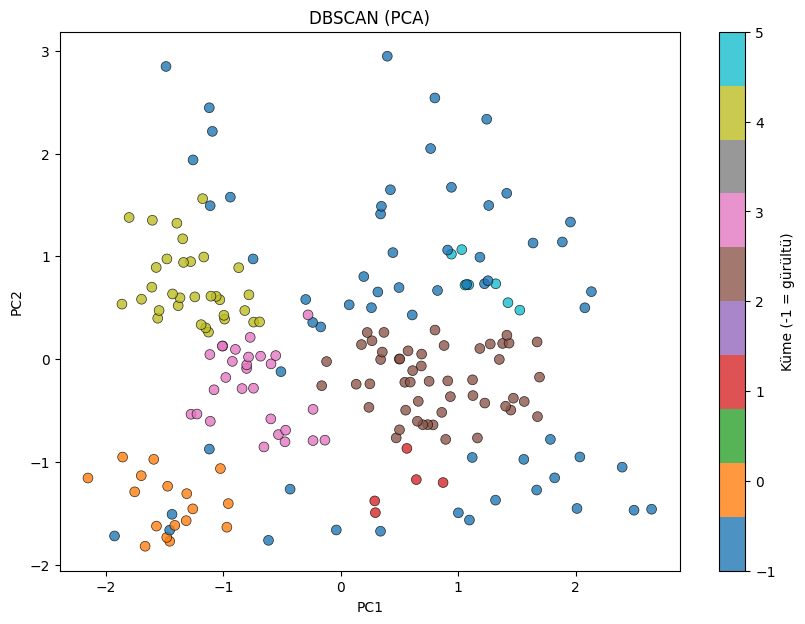

In [17]:
plt.figure(figsize=(10,7))
scatter = plt.scatter(X_pca[:,0],X_pca[:,1],c=dbscan_labels,cmap="tab10",alpha=0.8,s=50,edgecolors="k",linewidth=0.5)
plt.colorbar(scatter,label="Küme (-1 = gürültü)")
plt.title("DBSCAN (PCA)")
plt.xlabel("PC1")
plt.ylabel("PC2")
plt.show()

#### üç yöntemi karşılaştıralım

In [18]:
def cluster_scores(X,labels):
    return {
        "Küme": len(set(labels)-{-1}),
        "Silhouette": silhouette_score(X,labels),
        "Davies-Bouldin": davies_bouldin_score(X,labels),
        "Calinski-Harabasz": calinski_harabasz_score(X,labels),
    }

pd.DataFrame({
    "K-Means": cluster_scores(X_scaled,kmeans_labels),
    "Hiyerarşik": cluster_scores(X_scaled,agg_labels),
    "DBSCAN": cluster_scores(X_scaled[mask],dbscan_labels[mask]),
}).T

,Küme,Silhouette,Davies-Bouldin,Calinski-Harabasz
K-Means,6.0,0.428417,0.825354,135.102104
Hiyerarşik,6.0,0.420117,0.852102,127.986454
DBSCAN,6.0,0.481715,0.638575,117.804913


#### Decision Tree: processed.cleveland.data

In [19]:
column_names = ["age","sex","cp","trestbps","chol","fbs","restecg",
                "thalach","exang","oldpeak","slope","ca","thal","target"]
df_heart = pd.read_csv("processed.cleveland.data",header=None,names=column_names,na_values="?")
df_heart = df_heart.dropna()
df_heart["disease"] = (df_heart["target"]>0).astype(int)
df_heart = df_heart.drop(columns=["target"])
df_heart = pd.get_dummies(df_heart,columns=["cp","restecg","slope","thal"],drop_first=True,dtype=int)

X = df_heart.drop(columns=["disease"])
y = df_heart["disease"]

X_train,X_test,y_train,y_test = train_test_split(X,y,test_size=0.2,random_state=SEED,stratify=y)
cv = StratifiedKFold(n_splits=5,shuffle=True,random_state=SEED)
print("Train:", X_train.shape, "Test:", X_test.shape)

Train: (237, 18) Test: (60, 18)


In [20]:
dt_grid = GridSearchCV(DecisionTreeClassifier(random_state=SEED),
                       param_grid={
                           "criterion":["gini","entropy"],
                           "splitter":["best","random"],
                           "max_depth":[3,4,5,6,8,None],
                           "min_samples_leaf":[1,2,5,10]
                       },
                       cv=cv,scoring="accuracy",n_jobs=-1)
dt_grid.fit(X_train,y_train)
dt = dt_grid.best_estimator_
print("En iyi parametre:", dt_grid.best_params_)
print("En iyi CV skoru:", dt_grid.best_score_)

En iyi parametre: {'criterion': 'gini', 'max_depth': 3, 'min_samples_leaf': 10, 'splitter': 'best'}
En iyi CV skoru: 0.8439716312056736


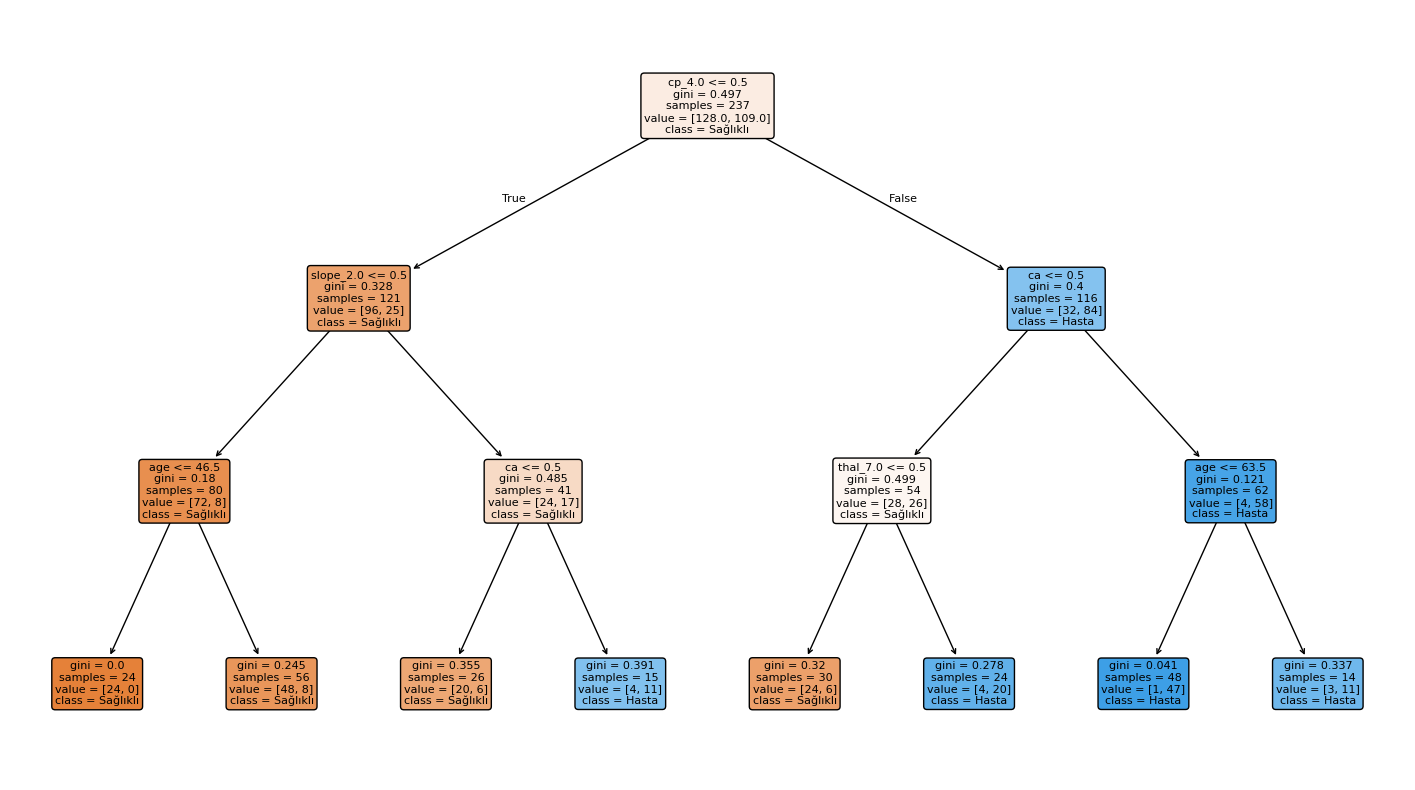

In [21]:
plt.figure(figsize=(18,10))
plot_tree(dt,feature_names=X.columns,class_names=["Sağlıklı","Hasta"],filled=True,rounded=True,fontsize=8)
plt.show()

#### Random Forest

In [22]:
rf_grid = GridSearchCV(RandomForestClassifier(random_state=SEED),
                       param_grid={
                           "n_estimators":[100,200],
                           "max_depth":[3,5,None],
                           "min_samples_leaf":[1,3],
                           "max_features":["sqrt","log2"]
                       },
                       cv=cv,scoring="accuracy",n_jobs=-1)
rf_grid.fit(X_train,y_train)
rf = rf_grid.best_estimator_
print("En iyi parametre:", rf_grid.best_params_)
print("En iyi CV skoru:", rf_grid.best_score_)

En iyi parametre: {'max_depth': 3, 'max_features': 'sqrt', 'min_samples_leaf': 3, 'n_estimators': 200}
En iyi CV skoru: 0.8271276595744681


In [23]:
rows = []
for name,model in [("Decision Tree",dt),("Random Forest",rf)]:
    cv_scores = cross_val_score(model,X_train,y_train,cv=cv,scoring="accuracy")
    rows.append({
        "Model": name,
        "Train": accuracy_score(y_train,model.predict(X_train)),
        "Test": accuracy_score(y_test,model.predict(X_test)),
        "CV Ort.": cv_scores.mean(),
        "CV Std": cv_scores.std(),
    })
pd.DataFrame(rows).set_index("Model")

,Train,Test,CV Ort.,CV Std
Model,,,,
Decision Tree,0.864979,0.816667,0.843972,0.036237
Random Forest,0.864979,0.816667,0.827128,0.074870


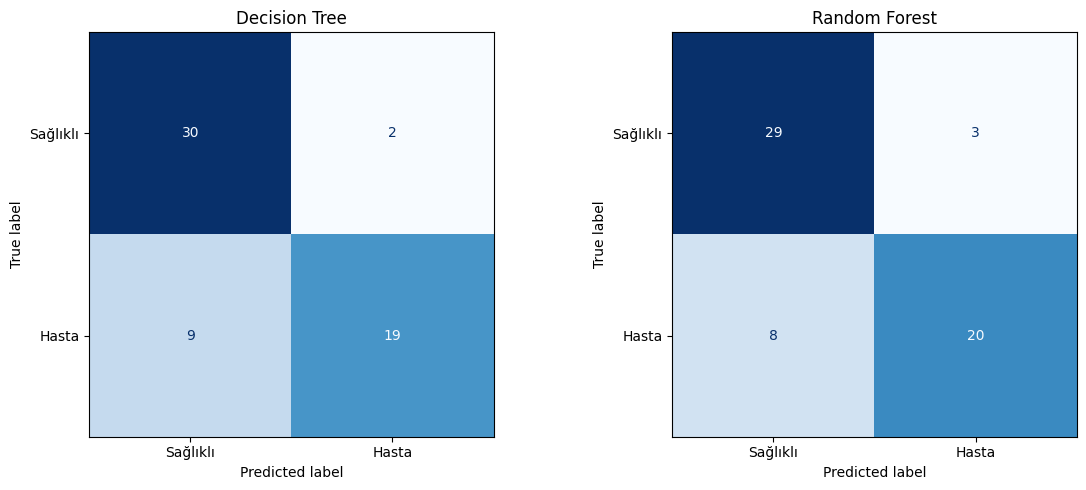

In [24]:
fig, axes = plt.subplots(1,2,figsize=(12,5))
for ax,(name,model) in zip(axes,[("Decision Tree",dt),("Random Forest",rf)]):
    ConfusionMatrixDisplay.from_estimator(model,X_test,y_test,display_labels=["Sağlıklı","Hasta"],cmap="Blues",ax=ax,colorbar=False)
    ax.set_title(name)
plt.tight_layout()
plt.show()

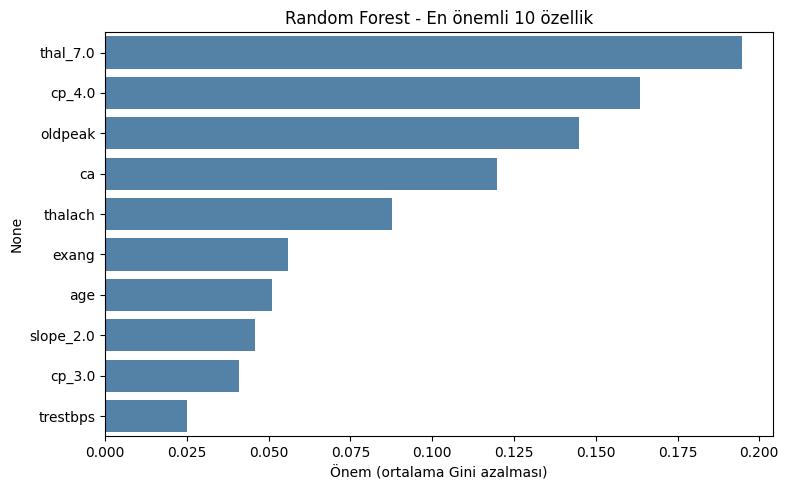

In [25]:
imp = pd.Series(rf.feature_importances_,index=X.columns).nlargest(10)
plt.figure(figsize=(8,5))
sns.barplot(x=imp.values,y=imp.index,color="steelblue")
plt.xlabel("Önem (ortalama Gini azalması)")
plt.title("Random Forest - En önemli 10 özellik")
plt.tight_layout()
plt.show()

#### Ensemble modelleri karşılaştıralım

In [26]:
models = {
    "Random Forest": RandomForestClassifier(n_estimators=200,random_state=SEED,n_jobs=-1),
    "AdaBoost": AdaBoostClassifier(estimator=DecisionTreeClassifier(max_depth=3),n_estimators=300,learning_rate=0.01,random_state=SEED),
    "Gradient Boosting": GradientBoostingClassifier(n_estimators=300,learning_rate=0.01,max_depth=3,subsample=0.8,random_state=SEED),
    "HistGradientBoosting": HistGradientBoostingClassifier(max_iter=300,learning_rate=0.05,random_state=SEED),
    "XGBoost": XGBClassifier(n_estimators=300,learning_rate=0.05,max_depth=4,subsample=0.8,colsample_bytree=0.8,reg_lambda=1.0,
    eval_metric="logloss",random_state=SEED,n_jobs=-1),
    "LightGBM": LGBMClassifier(n_estimators=300,learning_rate=0.05,num_leaves=15,subsample=0.8,subsample_freq=1,colsample_bytree=0.8,
    random_state=SEED,verbose=-1,n_jobs=-1),
    "CatBoost": CatBoostClassifier(iterations=300,learning_rate=0.05,depth=4,random_seed=SEED,verbose=0),
}

In [27]:
rows = []
for name,model in models.items():
    t0 = time.time()
    cvr = cross_validate(model,X_train,y_train,cv=cv,scoring=["accuracy","roc_auc"],n_jobs=1)
    model.fit(X_train,y_train)
    proba = model.predict_proba(X_test)[:,1]
    pred = (proba>=0.5).astype(int)
    rows.append({
        "Model": name,
        "CV Acc": cvr["test_accuracy"].mean(),
        "CV Acc Std": cvr["test_accuracy"].std(),
        "CV AUC": cvr["test_roc_auc"].mean(),
        "Test Acc": accuracy_score(y_test,pred),
        "Test AUC": roc_auc_score(y_test,proba),
        "Süre (s)": time.time()-t0,
    })
    print(name,"tamamlandı")

results = pd.DataFrame(rows).sort_values("CV AUC",ascending=False).reset_index(drop=True)
results

Random Forest tamamlandı
AdaBoost tamamlandı
Gradient Boosting tamamlandı
HistGradientBoosting tamamlandı
XGBoost tamamlandı
LightGBM tamamlandı
CatBoost tamamlandı


,Model,CV Acc,CV Acc Std,CV AUC,Test Acc,Test AUC,Süre (s)
0,Gradient Boosting,0.814184,0.045914,0.894295,0.800000,0.921875,1.470127
1,Random Forest,0.801684,0.066594,0.893727,0.833333,0.928571,1.796189
2,LightGBM,0.793174,0.049501,0.887991,0.833333,0.922991,0.219884
3,AdaBoost,0.822606,0.051918,0.885804,0.766667,0.897321,2.437574
4,XGBoost,0.788830,0.057716,0.880699,0.866667,0.914062,0.792649
5,HistGradientBoosting,0.784929,0.057129,0.877553,0.833333,0.883929,0.990356
6,CatBoost,0.767642,0.056464,0.870116,0.833333,0.917411,1.817952


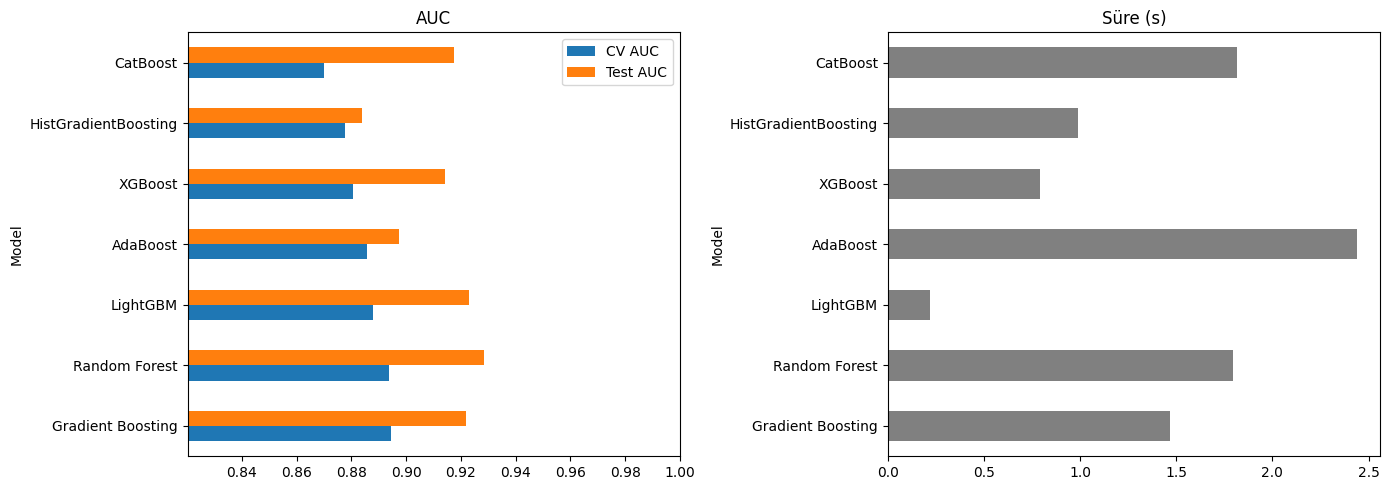

In [28]:
fig, axes = plt.subplots(1,2,figsize=(14,5))
results.set_index("Model")[["CV AUC","Test AUC"]].plot(kind="barh",ax=axes[0])
axes[0].set_xlim(results[["CV AUC","Test AUC"]].min().min()-0.05,1)
axes[0].set_title("AUC")
results.set_index("Model")["Süre (s)"].plot(kind="barh",ax=axes[1],color="gray")
axes[1].set_title("Süre (s)")
plt.tight_layout()
plt.show()

### Çalışma değerlendirmesi

Çapraz doğrulama puanlarını test puanı ve çalışma süresiyle birlikte okumak model seçimini dengeler.


### Ek değerlendirme: doğrulama ve test farkı

**Amaç:** Modellerin çapraz doğrulama AUC değeri ile test AUC değeri arasındaki farkı görünür kılmak.

**Yorum:** Büyük fark, veri bölünmesine duyarlılık veya aşırı uyum olasılığına işaret edebilir. Çalışma süresi de model seçiminin pratik maliyetidir.

In [ ]:
karsilastirma = results[["Model", "CV AUC", "Test AUC", "Süre (s)"]].copy()
karsilastirma["AUC farkı"] = (karsilastirma["CV AUC"] - karsilastirma["Test AUC"]).abs()
print(karsilastirma.sort_values("AUC farkı").round(3).to_string(index=False))